# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in decimal MB
frame_mb = 1920 * 1080 * 3 / 1_000_000

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 60 * 60

# TODO 3: 400 cameras x 24 h, uncompressed, in TiB (1 TB as defined: 1024^4 bytes)
fleet_bytes = 1920 * 1080 * 3 * frames_per_day * 400
fleet_tb = fleet_bytes / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps
small_bytes = 640 * 360 * 3 * (10 * 24 * 60 * 60) * 400
fleet_tb_small = small_bytes / (1024 ** 4)
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 6.22 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Your answer:** Spatially, a small or distant object (such as a person's hand, face, or a small item) may occupy too few pixels at 360p to identify. Temporally, reducing 30 fps to 10 fps discards two out of every three frames, so a brief action or the exact order/timing of movements between retained frames may disappear.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

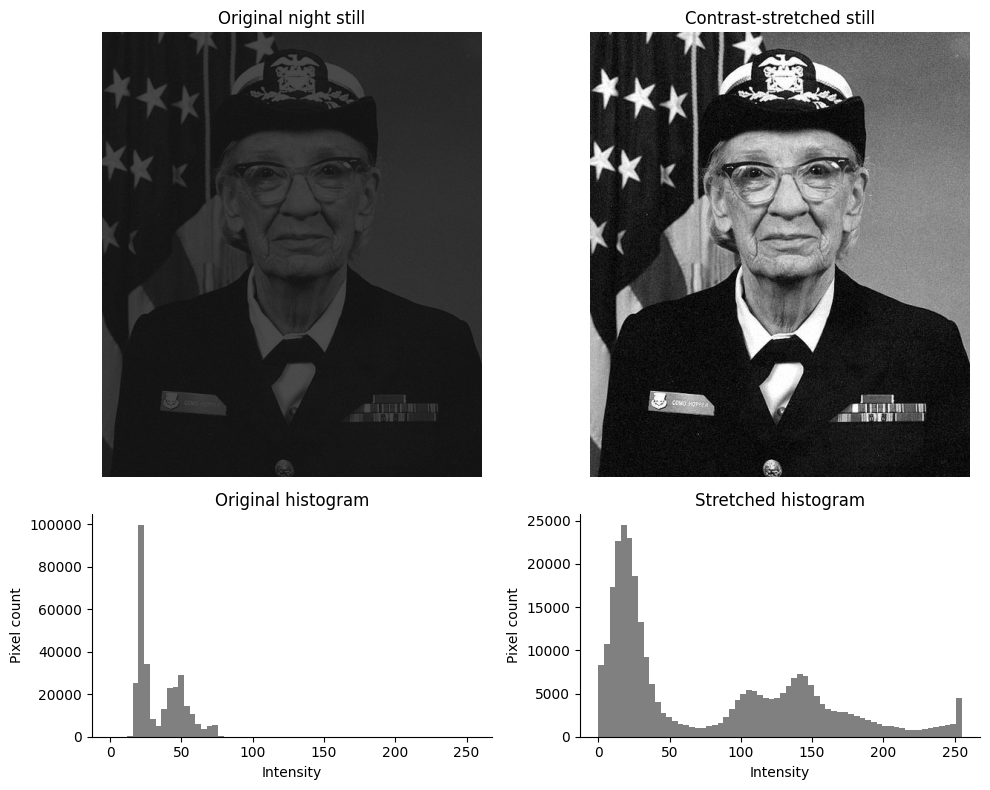

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# Robust limits and contrast before enhancement
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# Map the 1st percentile to 0 and 99th percentile to 255
stretched = np.clip((night_still - p1) * 255 / (p99 - p1), 0, 255)
s1, s99 = np.percentile(stretched, [1, 99])
c_after = michelson(s99, s1)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original night still")
axes[0, 0].axis("off")
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-stretched still")
axes[0, 1].axis("off")
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="gray")
axes[1, 0].set_title("Original histogram")
axes[1, 0].set_xlabel("Intensity"); axes[1, 0].set_ylabel("Pixel count")
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="gray")
axes[1, 1].set_title("Stretched histogram")
axes[1, 1].set_xlabel("Intensity"); axes[1, 1].set_ylabel("Pixel count")
plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Your answer:** The original histogram is narrow and concentrated toward the dark/low-intensity end, which is the lecture's low-contrast, underexposed pattern. Stretching spreads the occupied intensity range across 0–255, making differences that were already present easier to see; it changes the display mapping, not the underlying scene information, and cannot recover clipped or never-recorded detail. A histogram contains only counts of intensity values, not their spatial arrangement, so two completely different scenes can have the same histogram.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing ranges (speed < 3 px/s): [(68.7, 78.1)]
Running ranges (speed > 25 px/s): [(78.6, 86.0)]
First audio threshold event: (2250, np.float64(75.0))
Lighting jump event: (3000, np.float64(100.0))


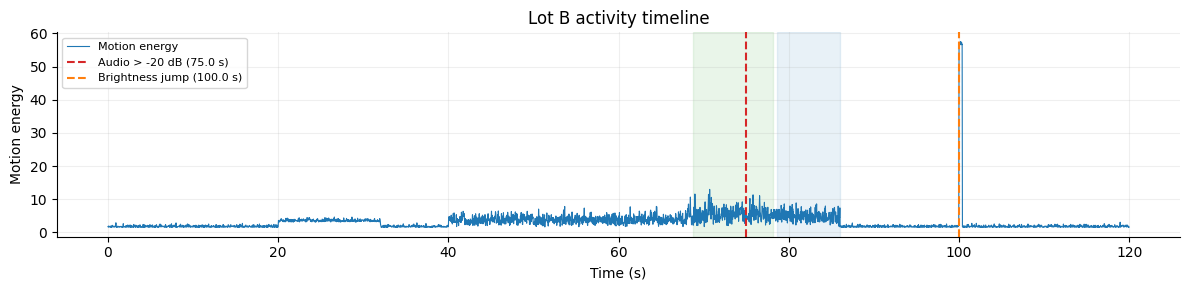

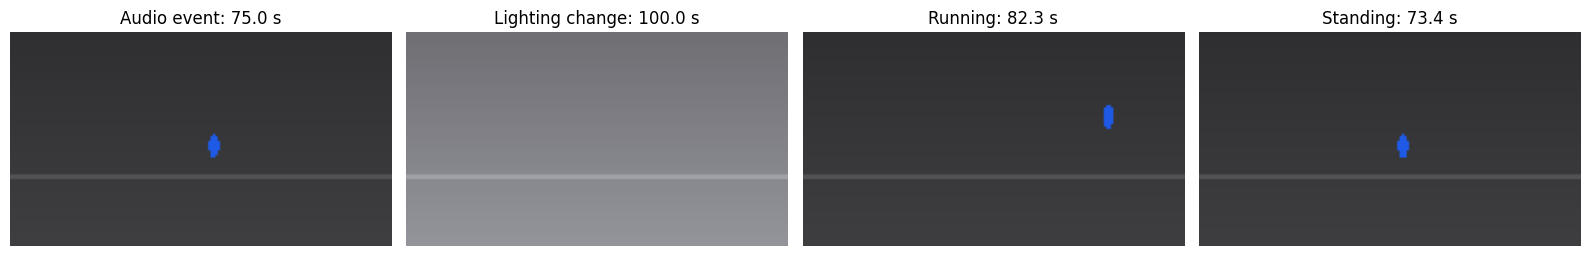

In [4]:
# TODO 1: one-second displacement magnitude (px/s), using a 30-frame difference
cctv = cctv.copy()
dx = cctv["person_x"] - cctv["person_x"].shift(FPS)
dy = cctv["person_y"] - cctv["person_y"].shift(FPS)
speed = np.hypot(dx, dy)
valid_track = cctv["person_x"].notna() & cctv["person_x"].shift(FPS).notna()
speed = speed.where(valid_track)
cctv["person_speed"] = speed

# Group threshold hits, bridging only tiny tracking gaps (<= 0.2 s)
def time_ranges(mask, max_gap_frames=6, min_frames=6):
    idx = np.flatnonzero(mask.fillna(False).to_numpy())
    if len(idx) == 0:
        return []
    groups = np.split(idx, np.where(np.diff(idx) > max_gap_frames + 1)[0] + 1)
    return [(float(cctv.time_s.iloc[g[0]]), float(cctv.time_s.iloc[g[-1]]))
            for g in groups if len(g) >= min_frames]

standing_ranges = time_ranges(speed < 3)
running_ranges = time_ranges(speed > 25)
print("Standing ranges (speed < 3 px/s):", [(round(a, 2), round(b, 2)) for a, b in standing_ranges])
print("Running ranges (speed > 25 px/s):", [(round(a, 2), round(b, 2)) for a, b in running_ranges])

# TODO 3: first frame above -20 dB and frame(s) with >40 brightness jump
audio_hits = np.flatnonzero((cctv.audio_level_db > -20).to_numpy())
audio_event_idx = int(audio_hits[0]) if len(audio_hits) else None
lighting_hits = np.flatnonzero((cctv.mean_brightness.diff() > 40).to_numpy())
lighting_event_idx = int(lighting_hits[0]) if len(lighting_hits) else None
print("First audio threshold event:", None if audio_event_idx is None else (audio_event_idx, cctv.time_s.iloc[audio_event_idx]))
print("Lighting jump event:", None if lighting_event_idx is None else (lighting_event_idx, cctv.time_s.iloc[lighting_event_idx]))

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, lw=0.8, label="Motion energy")
if audio_event_idx is not None:
    ta = cctv.time_s.iloc[audio_event_idx]; ax.axvline(ta, color="tab:red", ls="--", label=f"Audio > -20 dB ({ta:.1f} s)")
if lighting_event_idx is not None:
    tl = cctv.time_s.iloc[lighting_event_idx]; ax.axvline(tl, color="tab:orange", ls="--", label=f"Brightness jump ({tl:.1f} s)")
for a, b in standing_ranges:
    ax.axvspan(a, b, color="tab:green", alpha=0.10)
for a, b in running_ranges:
    ax.axvspan(a, b, color="tab:blue", alpha=0.10)
ax.set(xlabel="Time (s)", ylabel="Motion energy", title="Lot B activity timeline")
ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per detected event
keyframe_indices = []
if audio_event_idx is not None: keyframe_indices.append(("Audio event", audio_event_idx))
if lighting_event_idx is not None: keyframe_indices.append(("Lighting change", lighting_event_idx))
if running_ranges:
    run_mid = (running_ranges[0][0] + running_ranges[0][1]) / 2
    keyframe_indices.append(("Running", int(np.argmin(np.abs(cctv.time_s - run_mid)))))
if standing_ranges:
    stand_mid = (standing_ranges[-1][0] + standing_ranges[-1][1]) / 2
    keyframe_indices.append(("Standing", int(np.argmin(np.abs(cctv.time_s - stand_mid)))))
fig, axs = plt.subplots(1, len(keyframe_indices), figsize=(4 * len(keyframe_indices), 3))
if len(keyframe_indices) == 1: axs = [axs]
for ax, (label, i) in zip(axs, keyframe_indices):
    ax.imshow(render_frame(cctv.iloc[i])); ax.set_title(f"{label}: {cctv.time_s.iloc[i]:.1f} s"); ax.axis("off")
plt.tight_layout(); plt.show()

**Your answer:** Uniform sampling every 20 seconds would most likely miss the short sound event at about 75 s and could miss the exact onset of the lighting change at 100 s; it may also show a person only in one state and miss the transition into running. The approach used here is **content-based keyframe extraction** (event-driven/keyframe selection), where frames are selected because activity or a measured signal changes.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

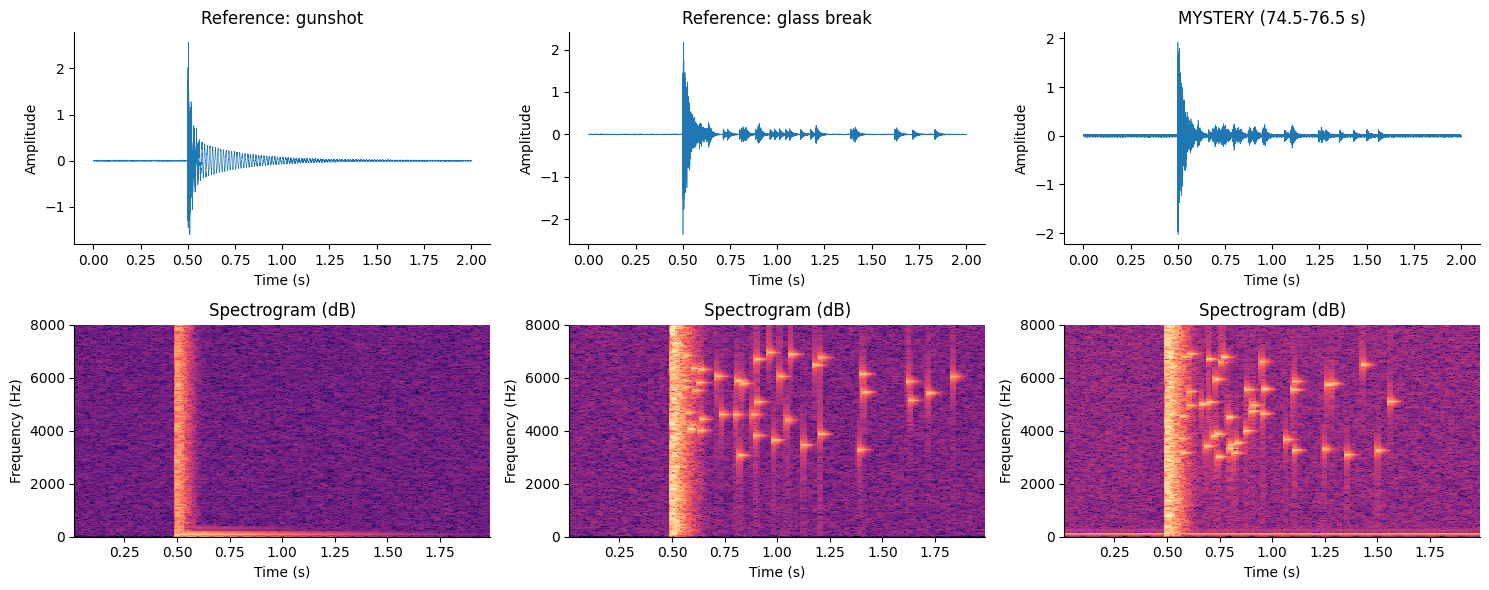

{'Reference: gunshot': 0.215, 'Reference: glass break': 0.638, 'MYSTERY (74.5-76.5 s)': 0.656}
Verdict: the mystery sound is most consistent with breaking glass (based on high-frequency spectral energy and spectrogram pattern).


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for col, (name, x) in enumerate(clips.items()):
    t = np.arange(len(x)) / FS
    axes[0, col].plot(t, x, lw=0.45)
    axes[0, col].set_title(name); axes[0, col].set_xlabel("Time (s)"); axes[0, col].set_ylabel("Amplitude")
    f, tt, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    axes[1, col].pcolormesh(tt, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma")
    axes[1, col].set_ylim(0, 8000); axes[1, col].set_xlabel("Time (s)"); axes[1, col].set_ylabel("Frequency (Hz)")
    axes[1, col].set_title("Spectrogram (dB)")
plt.tight_layout(); plt.show()

# Fraction of spectral energy above 3 kHz in 0.2–1.2 s after the 0.5 s impact
hf_fraction = {}
for name, x in clips.items():
    f, tt, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    time_mask = (tt >= 0.2) & (tt <= 1.2)
    total_energy = Sxx[:, time_mask].sum()
    high_energy = Sxx[(f > 3000), :][:, time_mask].sum()
    hf_fraction[name] = float(high_energy / total_energy)

print({k: round(v, 3) for k, v in hf_fraction.items()})
# Compare mystery with reference signatures; glass has a much larger sustained high-frequency fraction
verdict = "breaking glass" if hf_fraction["MYSTERY (74.5-76.5 s)"] > (hf_fraction["Reference: gunshot"] + hf_fraction["Reference: glass break"]) / 2 else "gunshot"
print(f"Verdict: the mystery sound is most consistent with {verdict} (based on high-frequency spectral energy and spectrogram pattern).")

**Your answer:** No. The waveforms mainly show amplitude over time, so both events can look like a sharp impact and are not reliably distinguishable by shape alone. A spectrogram adds **time, frequency and magnitude** (energy/intensity) in one view. The deciding pattern is the scattered, lingering high-frequency specks after the initial impact, which match the glass-break reference rather than the gunshot's brief broadband crack and low-frequency boom.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

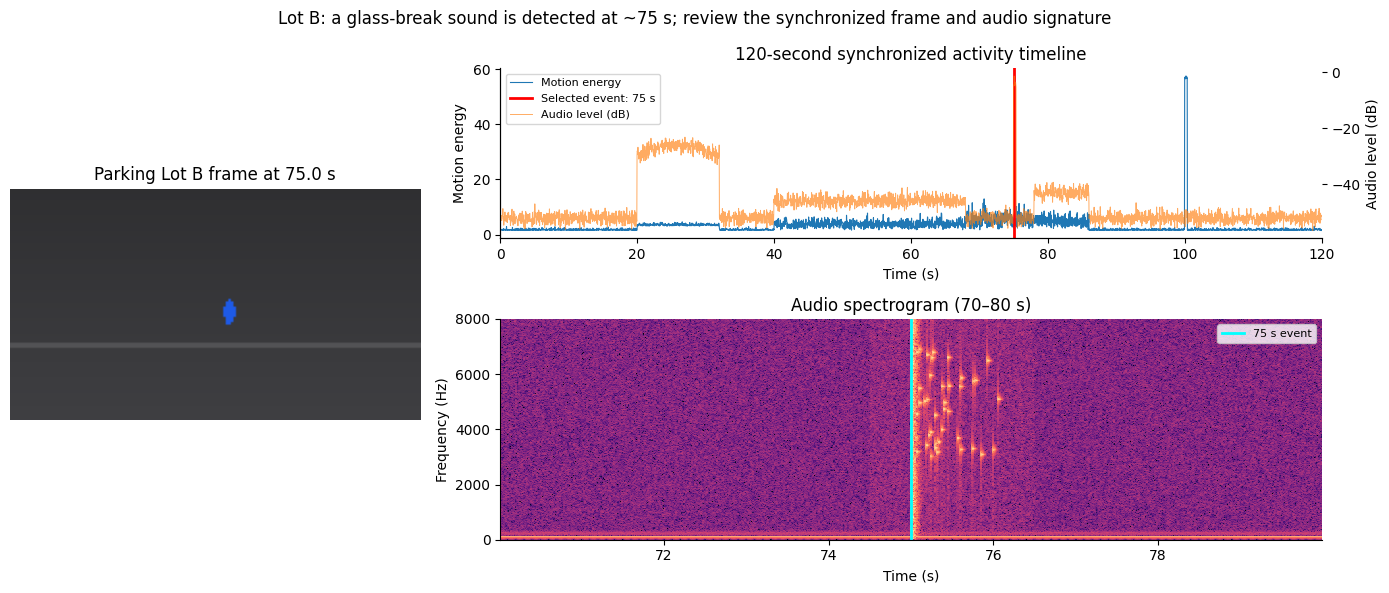

In [6]:
t_sel = 75.0
idx_sel = int(np.argmin(np.abs(cctv.time_s - t_sel)))
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])

# TODO 1: representative video frame at 75 s
ax_img = fig.add_subplot(gs[:, 0])
ax_img.imshow(render_frame(cctv.iloc[idx_sel]))
ax_img.set_title(f"Parking Lot B frame at {cctv.time_s.iloc[idx_sel]:.1f} s")
ax_img.axis("off")

# TODO 2: full motion + audio timeline, synchronized marker at 75 s
ax_t = fig.add_subplot(gs[0, 1])
ax_t.plot(cctv.time_s, cctv.motion_energy, label="Motion energy", lw=0.8)
ax_t.set_ylabel("Motion energy")
ax_audio = ax_t.twinx()
ax_audio.plot(cctv.time_s, cctv.audio_level_db, color="tab:orange", alpha=0.65, lw=0.7, label="Audio level (dB)")
ax_audio.set_ylabel("Audio level (dB)")
ax_t.axvline(t_sel, color="red", lw=2, label="Selected event: 75 s")
ax_t.set_xlim(0, 120); ax_t.set_title("120-second synchronized activity timeline"); ax_t.set_xlabel("Time (s)")
lines, labels = ax_t.get_legend_handles_labels(); lines2, labels2 = ax_audio.get_legend_handles_labels()
ax_t.legend(lines + lines2, labels + labels2, loc="upper left", fontsize=8)

# TODO 3: 70–80 s audio spectrogram with the same 75 s marker
ax_s = fig.add_subplot(gs[1, 1])
f, ts, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
mask = (ts >= 0) & (ts <= 10)
ax_s.pcolormesh(70 + ts[mask], f, 10 * np.log10(Sxx[:, mask] + 1e-12), shading="auto", cmap="magma")
ax_s.set_ylim(0, 8000); ax_s.set_xlabel("Time (s)"); ax_s.set_ylabel("Frequency (Hz)")
ax_s.axvline(t_sel, color="cyan", lw=2, label="75 s event")
ax_s.legend(loc="upper right", fontsize=8); ax_s.set_title("Audio spectrogram (70–80 s)")

# TODO 4: conclusion-style title
fig.suptitle("Lot B: a glass-break sound is detected at ~75 s; review the synchronized frame and audio signature", fontsize=12)
plt.tight_layout(); plt.show()

**Your answer:** A +2 s audio offset would make the sound appear to occur at 77 s while the video frame at 75 s is displayed, potentially linking the sound to the wrong action or person. The audio spectrogram panel would make the mismatch visible because its event marker/signature would not line up with the corresponding event on the shared timeline. Correct synchronization is essential before drawing a causal conclusion.

**Final briefing:** The Lot B log shows a loud acoustic event beginning at approximately **75.0 s**, coincident with the camera's audio-level threshold crossing; the sound signature is most consistent with **breaking glass**, while a marked lighting change occurs later at **100.0 s** and the tracked person runs during the later portion of the clip (approximately 78.6–86.0 s). I would put the **synchronized multimodal view** first because it gives an overview of change and events while linking the video, motion and audio to one common time reference. The spectrogram's time–frequency–magnitude pattern supports the glass-break classification more strongly than the waveform alone. Uncompressed 1080p/30 fps recording across 400 cameras would require an impractical amount of daily storage, so lower-resolution/lower-frame-rate recording or compression should be considered with event-triggered high-quality retention. However, the policy must not sacrifice the temporal evidence around the impact: retain enough frame rate and original audio around approximately 75 s to preserve the order and timing of the event.